In [1]:
import gdown
import pandas as pd
import duckdb
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns

pd.options.display.float_format = '{:.2f}'.format

file_id = '1_U2orSaVifT4KjQr0ibAxYVn0EmM4t7O'
url = f'https://drive.google.com/uc?export=download&id={file_id}'
gdown.download(url, 'sm_small_random.csv', quiet=True)

raw_df = pd.read_csv('sm_small_random.csv')

con = duckdb.connect()
con.execute("SET enable_progress_bar = false")
con.execute("SET enable_progress_bar_print = false")
con.register("raw_events", raw_df);

In [2]:
query = """
select *
from raw_events
limit 1
"""
con.execute(query).df()

,device_type,event_id,user_id,user_is_authorized,location_id,create_timestamp,product_id,product_is_pick_up,product_is_pick_point,product_is_delivery,product_is_now,product_price,product_category,product_gender,product_age,brand_lvl,add_to_cart_flag,create_order_flag
0,mobileapp_android,43dde787-184a-4df0-b07e-3fb612d2fca9,16,0,1584,2024-06-15T20:03:00.866Z,28716,0.00,1.00,1.00,0.00,3289,одежда,унисекс,взрослые,0,1,0


In [3]:
query = """
with
temp_table_1 as (
  select
    count(*) as uniq_row_count
  from (select distinct * from raw_events) as deduplicated_table
)

select
  count (distinct user_id) as uniq_user_count,
  count(*) as row_count,
  uniq_row_count,
  (row_count - uniq_row_count) as row_duplicates,
  max(create_timestamp) as max_datetime,
  min(create_timestamp) as min_datetime
from temp_table_1, raw_events
group by uniq_row_count
"""
con.execute(query).df()

,uniq_user_count,row_count,uniq_row_count,row_duplicates,max_datetime,min_datetime
0,300000,996899,996895,4,2024-06-21T09:20:01.090Z,2024-06-01T00:00:11.711Z


Найдены следующие проблемы с данными:
- 4 одинаковые строки в датасете. Дубликаты нужно убрать.
- 21 июня 2024 неполный день. Для анализа необходимо взять полные дни с 1 до 20 июня 2024 включительно.

In [4]:
query = """
create or replace temp view funnel_mart as
select
  user_id,
  user_is_authorized,
  event_id,
  create_timestamp,
  device_type,
  add_to_cart_flag,
  create_order_flag,
  product_price
from (
  select
    distinct *
  from raw_events
  where date (create_timestamp) > '2024-05-31' and date(create_timestamp) < '2024-06-21'
  ) as uniq_filtered_table
"""
con.execute(query)

query = """
select *
from funnel_mart
limit 1
"""
con.execute(query).df()

,user_id,user_is_authorized,event_id,create_timestamp,device_type,add_to_cart_flag,create_order_flag,product_price
0,528541,1,363440d1-e3c6-46c0-8c5a-708ad1251097,2024-06-15T23:19:06.181Z,mobileapp_ios,0,0,4959


In [5]:
query = """
with
temp_table_2 as (
  select
    count(*) as uniq_row_count
  from (select distinct * from funnel_mart) as distinct_table
)

select
  count(distinct user_id) as uniq_user_count,
  count(*) as row_count,
  uniq_row_count,
  (row_count - uniq_row_count) as row_duplicates,
  max(create_timestamp) as max_datetime,
  min(create_timestamp) as min_datetime,
  count(case when add_to_cart_flag = 0 and create_order_flag = 1 then event_id end) as funnel_logic_violation_count
from temp_table_2, funnel_mart
group by uniq_row_count
"""
con.execute(query).df()

,uniq_user_count,row_count,uniq_row_count,row_duplicates,max_datetime,min_datetime,funnel_logic_violation_count
0,298018,988154,988154,0,2024-06-20T23:59:59.491Z,2024-06-01T00:00:11.711Z,0


In [6]:
query = """
select
  user_id,
  date(create_timestamp) as date,
  count(event_id) as view_count
from funnel_mart
group by user_id, date
order by view_count desc
limit 10
"""
con.execute(query).df()

,user_id,date,view_count
0,637699,2024-06-15,359
1,523088,2024-06-14,311
2,518106,2024-06-19,215
3,604158,2024-06-04,211
4,1817354,2024-06-02,158
5,637699,2024-06-14,113
6,1664347,2024-06-04,94
7,615828,2024-06-19,87
8,1927736,2024-06-06,75
9,214920,2024-06-02,70


## **Исследование распределения пользовательской активности**

In [7]:
df_funnel_mart = con.execute('select * from funnel_mart').df()

funnel_mart_summary = pd.DataFrame({
    'missing': df_funnel_mart.isnull().sum(),
    'uniq_count': df_funnel_mart.nunique(),
    'dtypes': df_funnel_mart.dtypes})

funnel_mart_summary

,missing,uniq_count,dtypes
user_id,0,298018,int64
user_is_authorized,0,2,int64
event_id,0,988154,str
create_timestamp,0,987731,str
device_type,0,3,str
add_to_cart_flag,0,2,int64
create_order_flag,0,2,int64
product_price,0,5846,int64


In [8]:
df_funnel_mart['create_timestamp'] = pd.to_datetime(df_funnel_mart['create_timestamp'], format='ISO8601')
df_funnel_mart['date'] = df_funnel_mart['create_timestamp'].dt.floor('D')

views_per_user_per_day = df_funnel_mart.groupby(['user_id', 'date'], as_index=False)\
    .agg({'event_id' : 'count'})\
    .rename(columns={'event_id':'view_count'})

In [9]:
views_per_user_per_day['view_count'].describe(percentiles = [0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999])

count   499824.00
mean         1.98
std          2.17
min          1.00
25%          1.00
50%          1.00
75%          2.00
90%          4.00
95%          5.00
99%         10.00
99.9%       21.00
max        359.00
Name: view_count, dtype: float64

In [10]:
anomalous_user_days = views_per_user_per_day.query('view_count > 21')
active_days_per_user = views_per_user_per_day.groupby('user_id').size()

inspection = pd.DataFrame({
    'Проверка': [
        'Аномально активные пользователи',
        'Аномальные пользовательские дни',
        'Были активны несколько дней',
        'Были активны только один день',
        'Имели несколько аномальных дней'],
    'Результат': [
        anomalous_user_days['user_id'].nunique(),
        len(anomalous_user_days),
        active_days_per_user.loc[
            anomalous_user_days['user_id'].unique()
        ].gt(1).sum(),
        active_days_per_user.loc[
            anomalous_user_days['user_id'].unique()
        ].eq(1).sum(),
        anomalous_user_days.groupby('user_id').size().gt(1).sum()]
})

inspection

,Проверка,Результат
0,Аномально активные пользователи,373
1,Аномальные пользовательские дни,449
2,Были активны несколько дней,319
3,Были активны только один день,54
4,Имели несколько аномальных дней,42


In [11]:
query = """
create or replace temp view views_per_user_per_day as
select
  user_id,
  date(create_timestamp) as date,
  count(event_id) as view_count
from funnel_mart
group by user_id, date
"""
con.execute(query);

In [12]:
query = """
select
  count(distinct case when view_count > 21 then user_id end) as anomalous_user_count,
  count(distinct user_id) as uniq_user_count,
  round(100.0*(anomalous_user_count / uniq_user_count), 2) as anomalous_user_percentage
from views_per_user_per_day
"""
con.execute(query).df()

,anomalous_user_count,uniq_user_count,anomalous_user_percentage
0,373,298018,0.13


**Выводы:**
- Среднее количество просмотров карточек товаров в активный пользовательский день составляет ~2.
- В 99% активных пользовательских дней зафиксировано не более 10 просмотров в день. В 99,9% активных пользовательских дней зафиксирован не более чем 21 просмотр.
- Выявлены 373 пользователя, которые хотя бы 1 день превысили порог в 21 просмотр. Их доля составила 0,13% аналитической выборки.
- Необходимо сначала провести основной анализ по полной выборке, а затем провести проверку чувствительности и по ее результатам решить исключать ли этих пользователей из анализа воронки.

## **Накопительная пользовательская воронка за период с 1-20 июня 2024 года**

In [13]:
user_based_cumulative_funnel_query = """
with
user_funnel as (
select
  user_id,
  1 as viewed,
  max(add_to_cart_flag) as carted,
  max(create_order_flag) as ordered
from funnel_mart
group by user_id
)

select
  sum(viewed)::integer as users_viewed,
  sum(carted)::integer as users_carted,
  sum(ordered)::integer as users_ordered,
  round(100.0*(users_carted / users_viewed), 2) as user_view_to_cart_cr,
  round(100.0*(users_ordered / users_carted), 2) as user_cart_to_order_cr,
  round(100.0*(users_ordered / users_viewed), 2) as user_view_to_order_cr
from user_funnel
"""
con.execute(user_based_cumulative_funnel_query).df()

,users_viewed,users_carted,users_ordered,user_view_to_cart_cr,user_cart_to_order_cr,user_view_to_order_cr
0,298018,88685,29396,29.76,33.15,9.86


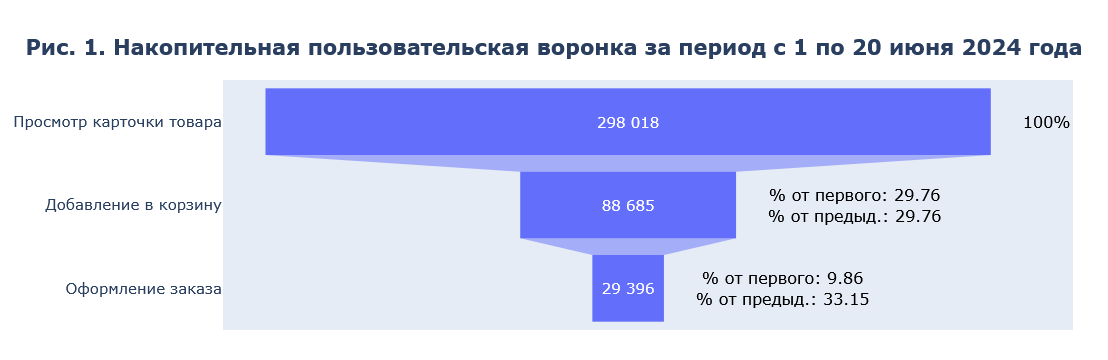

In [14]:
funnel_viz_df = con.execute(user_based_cumulative_funnel_query).df()
row = funnel_viz_df.iloc[0]

stages = ["Просмотр карточки товара", "Добавление в корзину", "Оформление заказа"]
values = [int(row['users_viewed']), int(row['users_carted']), int(row['users_ordered'])]

inside_labels = [f"{v:,}".replace(",", " ") for v in values]

outside_labels = [
    "100%",
    f"% от первого: {row['user_view_to_cart_cr']}<br>% от предыд.: {row['user_view_to_cart_cr']}",
    f"% от первого: {row['user_view_to_order_cr']}<br>% от предыд.: {row['user_cart_to_order_cr']}"
]

fig = px.funnel(
    x=values,
    y=stages,
    text=inside_labels,
    title="Рис. 1. Накопительная пользовательская воронка за период с 1 по 20 июня 2024 года"
)

fig.update_traces(
    textposition='inside',
    texttemplate="%{text}",
    hoverinfo='skip',
    hovertemplate=None
)

annotations = []

gap = 12000

for i, stage in enumerate(stages):
    x_pos = (values[i] / 2) + gap

    annotations.append(dict(
        x=x_pos,
        y=stage,
        text=outside_labels[i],
        xanchor='left',
        yanchor='middle',
        showarrow=False,
        font=dict(size=16, color="black")
    ))

fig.update_layout(
    title={
        'text': "<b>Рис. 1. Накопительная пользовательская воронка за период с 1 по 20 июня 2024 года<b>",
        'x': 0.5,
        'xanchor': 'center',
        'yanchor': 'top'
    },
    font=dict(size=15),
    showlegend=False,
    yaxis_title=None,
    annotations=annotations,
    margin=dict(l=35, r=35, t=80, b=30)
)

fig.show()


**Наблюдения по воронке:**

1. Между просмотром карточки товара и добавлением товара в корзину потеряно 209 333 пользователя, т.е. 70,24% пользователей, начавших воронку. Такие потери на первом шаге - это норма для электронной коммерции, т.к. пользователям необходимо посмотреть товары, сравнить их, почитать отзывы.
2. Между добавлением товара в корзину и созданием заказа потеряно ещё 59 289 (66,85%) пользователей, добавивших товар в корзину.
3. Итоговая конверсия из просмотра карточки товара в создание заказа составляет 9,86%.

Полученные значения показывают, на каком этапе сосредоточен основной объем потерь, но сами по себе не объясняют их причины. Для локализации потенциального барьера необходимо сравнить продуктовые сегменты.

## **Накопительная пользовательская воронка за период в разрезе устройств**

In [15]:
device_type_funnel_query = """
with
device_type_funnel as (
select
  user_id,
  device_type,
  1 as viewed,
  max(add_to_cart_flag) as carted,
  max(create_order_flag) as ordered
from funnel_mart
group by user_id, device_type
)

select
  device_type,
  sum(viewed)::integer as users_viewed,
  sum(carted)::integer as users_carted,
  sum(ordered)::integer as users_ordered,
  round(100.0*(users_carted / users_viewed), 2) as user_view_to_cart_cr,
  round(100.0*(users_ordered / users_carted), 2) as user_cart_to_order_cr,
  round(100.0*(users_ordered / users_viewed), 2) as user_view_to_order_cr,
from device_type_funnel
group by device_type
order by user_view_to_order_cr desc
"""
con.execute(device_type_funnel_query).df()

,device_type,users_viewed,users_carted,users_ordered,user_view_to_cart_cr,user_cart_to_order_cr,user_view_to_order_cr
0,mobileapp_android,139378,48411,16674,34.73,34.44,11.96
1,mobileapp_ios,91907,32204,10957,35.04,34.02,11.92
2,desktop,72727,9693,2229,13.33,23.00,3.06


**Наблюдения по воронке в разрезе устройств:**
1. **Desktop демонстрирует более низкие значения конверсии на всех этапах воронки по сравнению с мобильными приложениями**, но наихудший этап - это переход от просмотра до корзины (первый шаг), что норма для электронной коммерции. Здесь конверсия в 2,6 раза хуже, чем у мобильных устройств. А на втором шаге - только в 1,5 раза хуже, чем у мобильных.
2. Существенных различий в конверсии между платформами Android и iOS не наблюдается.

## **Накопительная пользовательская воронка за период в разрезе статусов авторизации**

In [16]:
auth_funnel_query = """
with
auth_funnel as (
select
  user_id,
  user_is_authorized,
  1 as viewed,
  max(add_to_cart_flag) as carted,
  max(create_order_flag) as ordered
from funnel_mart
group by user_id, user_is_authorized
)

select
  user_is_authorized,
  sum(viewed)::integer as users_viewed,
  sum(carted)::integer as users_carted,
  sum(ordered)::integer as users_ordered,
  round(100.0*(users_carted / users_viewed), 2) as user_view_to_cart_cr,
  round(100.0*(users_ordered / users_carted), 2) as user_cart_to_order_cr,
  round(100.0*(users_ordered / users_viewed), 2) as user_view_to_order_cr
from auth_funnel
group by user_is_authorized
order by user_view_to_order_cr desc
"""
con.execute(auth_funnel_query).df()

,user_is_authorized,users_viewed,users_carted,users_ordered,user_view_to_cart_cr,user_cart_to_order_cr,user_view_to_order_cr
0,1,220501,81933,29119,37.16,35.54,13.21
1,0,81034,7285,374,8.99,5.13,0.46


**Наблюдения по воронке в разрезе статусов авторизации:**
1. Авторизованные пользователи демонстрируют существенно более высокую конверсию на всех этапах воронки по сравнению с неавторизованными.
2. **Наихудший этап среди неавторизованных пользователей - этап перехода от корзины до оформления заказа (второй шаг)** - здесь конверсия в 6,9 раза хуже, чем у авторизованных. На этапе перехода от просмотра к корзине - конверсия неавторизованных хуже авторизованных только в 4,1 раза.

## **Анализ сочетания факторов (тип устройства + статус авторизации)**

In [17]:
device_auth_funnel_query = """
with
device_auth_funnel as (
select
  user_id,
  device_type,
  user_is_authorized,
  1 as viewed,
  max(add_to_cart_flag) as carted,
  max(create_order_flag) as ordered
from funnel_mart
group by user_id, device_type, user_is_authorized
)

select
  device_type,
  user_is_authorized,
  sum(viewed)::integer as users_viewed,
  sum(carted)::integer as users_carted,
  sum(ordered)::integer as users_ordered,
  round(100.0*(users_carted / users_viewed), 2) as user_view_to_cart_cr,
  round(100.0*(users_ordered / users_carted), 2) as user_cart_to_order_cr,
  round(100.0*(users_ordered / users_viewed), 2) as user_view_to_order_cr
from device_auth_funnel
group by device_type, user_is_authorized
order by user_view_to_order_cr desc
"""
con.execute(device_auth_funnel_query).df()

,device_type,user_is_authorized,users_viewed,users_carted,users_ordered,user_view_to_cart_cr,user_cart_to_order_cr,user_view_to_order_cr
0,mobileapp_ios,1,81663,30706,10832,37.60,35.28,13.26
1,mobileapp_android,1,127187,46769,16575,36.77,35.44,13.03
2,desktop,1,17481,6058,2167,34.65,35.77,12.40
3,mobileapp_ios,0,11806,1755,174,14.87,9.91,1.47
4,mobileapp_android,0,13988,1895,138,13.55,7.28,0.99
5,desktop,0,55246,3635,62,6.58,1.71,0.11


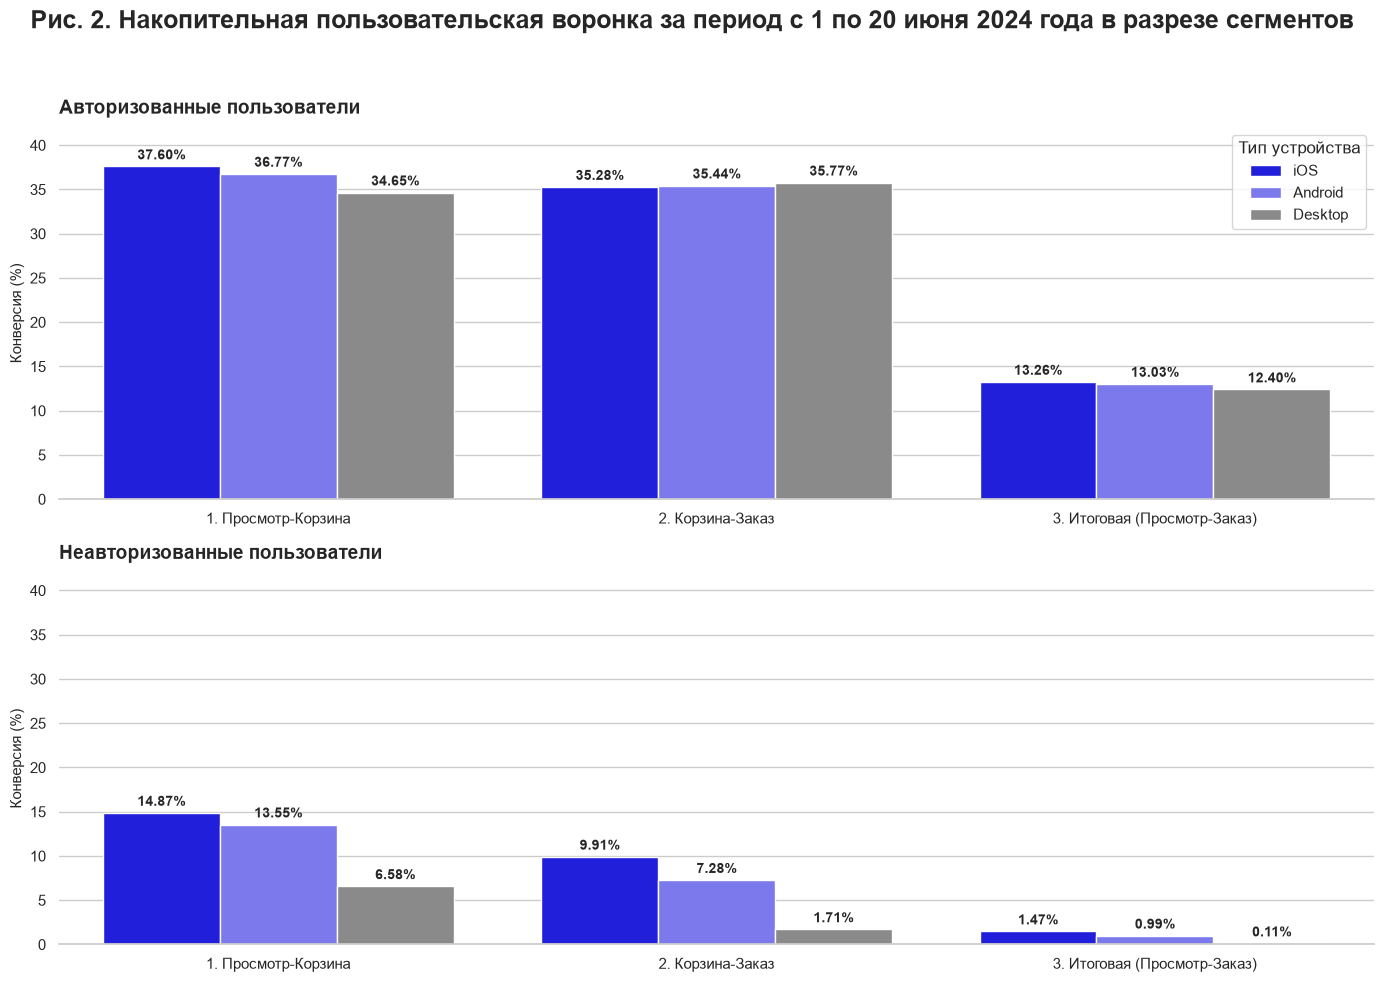

In [18]:
sns.set_theme(style="whitegrid")

viz_df = con.execute(device_auth_funnel_query).df()

device_rename = {'desktop': 'Desktop', 'mobileapp_android': 'Android', 'mobileapp_ios': 'iOS'}
viz_df['device_type'] = viz_df['device_type'].map(device_rename)

metrics = ['user_view_to_cart_cr', 'user_cart_to_order_cr', 'user_view_to_order_cr']
metric_names = ['1. Просмотр-Корзина', '2. Корзина-Заказ', '3. Итоговая (Просмотр-Заказ)']

df_melted = viz_df.melt(
    id_vars=['device_type', 'user_is_authorized'],
    value_vars=metrics,
    var_name='metric',
    value_name='conversion'
)

metric_map = dict(zip(metrics, metric_names))
df_melted['metric'] = df_melted['metric'].map(metric_map)

fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(14, 10), sharex=True, sharey=True)
fig.suptitle('Рис. 2. Накопительная пользовательская воронка за период с 1 по 20 июня 2024 года в разрезе сегментов',
             fontsize=18,
             fontweight='bold',
             y=0.98)

palette = {'iOS': '#0400F9', 'Android': '#6866FF', 'Desktop': '#8A8A8A'}

for row_idx, auth_status in enumerate([1, 0]):
    ax = axes[row_idx]
    status_text = 'Авторизованные пользователи' if auth_status == 1 else 'Неавторизованные пользователи'

    df_filtered = df_melted[df_melted['user_is_authorized'] == auth_status]

    sns.barplot(
        data=df_filtered,
        x='metric',
        y='conversion',
        hue='device_type',
        ax=ax,
        palette=palette,
        hue_order=['iOS', 'Android', 'Desktop']
    )

    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f%%', padding=3, fontsize=10, fontweight='bold')

    ax.set_title(status_text, fontsize=14, fontweight='bold', loc='left', pad=10)
    ax.set_xlabel('')
    ax.set_ylabel('Конверсия (%)', fontsize=11)
    ax.set_ylim(0, 42)

    ax.tick_params(axis='x', labelbottom=True, labelsize=11)

    if row_idx == 0:
        ax.legend(title='Тип устройства', loc='upper right')
    else:
        ax.legend().remove()

    sns.despine(ax=ax, left=True, bottom=False)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

**Наблюдения по воронке в разрезе сочетания сегментов:**
1. Конверсии авторизованных пользователей по устройствам на каждом этапе конверсии примерно одинаковые.
2. У неавторизованных пользователей худшая конверсия на Desktop на всех этапах воронки, а у неавторизованных пользователей мобильных устройств конверсии примерно похожи на всех этапах воронки.
3. **Конверсия неавторизованных пользователей Desktop хуже авторизованного Desktop сегмента** в 5,3 раза на первом шаге (Просмотр-Корзина), и **в 20,9 раз - на втором шаге (Корзина-Заказ)**.

In [19]:
priority_table = con.execute(device_auth_funnel_query).df()

priority_table = priority_table.assign(
    users_lost_before_order=(
        priority_table['users_viewed']
        - priority_table['users_ordered']
    )
)

priority_table[
    [
        'device_type',
        'user_is_authorized',
        'users_viewed',
        'users_ordered',
        'user_view_to_order_cr',
        'users_lost_before_order'
    ]
].sort_values(
    'users_lost_before_order',
    ascending=False
)

,device_type,user_is_authorized,users_viewed,users_ordered,user_view_to_order_cr,users_lost_before_order
1,mobileapp_android,1,127187,16575,13.03,110612
0,mobileapp_ios,1,81663,10832,13.26,70831
5,desktop,0,55246,62,0.11,55184
2,desktop,1,17481,2167,12.40,15314
4,mobileapp_android,0,13988,138,0.99,13850
3,mobileapp_ios,0,11806,174,1.47,11632


**Приоритизация сегментов с учетом абсолютных потерь:**

Наибольшие абсолютные потери от просмотра карточки товара до оформления заказа наблюдаются у авторизованных пользователей Android: 110 612 пользователей. Однако конверсия этого сегмента составляет 13,03% и практически совпадает с конверсией авторизованных пользователей iOS - 13,26%. Поэтому большой объем потерь в первую очередь связан с размером сегмента.

Авторизованные пользователи iOS находятся на втором месте по потерям, но здесь большой объем потерь так же объясняется размером сегмента при его конверсии в 13,26%.

У неавторизованных пользователей Desktop до создания заказа не дошли 55 184 пользователей. Это третье место по потерям. Итоговая конверсия сегмента составляет 0,11% против 0,99% на Android и 1,47% на iOS среди неавторизованных пользователей.

Следовательно, **неавторизованные пользователи настольной версии выбраны для дальнейшей диагностики не потому, что этот сегмент имеет максимальные абсолютные потери, а потому, что он сочетает значительный размер аудитории с наиболее выраженным отставанием конверсии.**


## **Проверка на пересечения**

In [20]:
query = """
with
user_segments as (
select
  user_id,
  count(distinct user_is_authorized) as auth_status_count,
  count(distinct device_type) as device_count
from funnel_mart
group by user_id
)

select
  count(*) filter (where auth_status_count > 1) as multi_auth_users,
  count(*) filter (where device_count > 1) as multi_device_users
from user_segments
"""
con.execute(query).df()

,multi_auth_users,multi_device_users
0,3517,5955


Фактические пересечения:
- 3 517 пользователей встречаются в обоих статусах;
- 5 955 используют несколько устройств.

## **Проверка устойчивости результата**

In [21]:
query = """
create or replace temp view anomalous_free_funnel_mart as
select *
from funnel_mart
where user_id not in (select distinct user_id from views_per_user_per_day where view_count > 21)
"""
con.execute(query);

In [22]:
anomalous_free_user_based_cumulative_funnel_query = """
with
user_funnel as (
select
  user_id,
  1 as viewed,
  max(add_to_cart_flag) as carted,
  max(create_order_flag) as ordered
from anomalous_free_funnel_mart
group by user_id
)

select
  sum(viewed)::integer as users_viewed,
  sum(carted)::integer as users_carted,
  sum(ordered)::integer as users_ordered,
  round(100.0*(users_carted / users_viewed), 2) as user_view_to_cart_cr,
  round(100.0*(users_ordered / users_carted), 2) as user_cart_to_order_cr,
  round(100.0*(users_ordered / users_viewed), 2) as user_view_to_order_cr
from user_funnel
"""
con.execute(anomalous_free_user_based_cumulative_funnel_query).df()

,users_viewed,users_carted,users_ordered,user_view_to_cart_cr,user_cart_to_order_cr,user_view_to_order_cr
0,297645,88389,29191,29.70,33.03,9.81


In [23]:
before = con.execute(user_based_cumulative_funnel_query).df().iloc[0]
after = con.execute(anomalous_free_user_based_cumulative_funnel_query).df().iloc[0]

metrics = ['user_view_to_cart_cr',
           'user_cart_to_order_cr',
           'user_view_to_order_cr']

inspection_summary = pd.DataFrame({'Без исключения': before[metrics],
                                   'После исключения': after[metrics],
                                   'Изменение, п.п.': after[metrics] - before[metrics]
                                   }).T

inspection_summary.style.format('{:.2f}')

,user_view_to_cart_cr,user_cart_to_order_cr,user_view_to_order_cr
Без исключения,29.76,33.15,9.86
После исключения,29.70,33.03,9.81
"Изменение, п.п.",-0.06,-0.12,-0.05


Исключение 373 аномально активных пользователей изменило межэтапные конверсии не более чем на 0,12 процентного пункта, а итоговую конверсию - на 0,05 процентного пункта. Основные выводы устойчивы к выбранному правилу фильтрации.

In [24]:
anomalous_free_device_auth_funnel_query = """
with
device_auth_funnel as (
select
  user_id,
  device_type,
  user_is_authorized,
  1 as viewed,
  max(add_to_cart_flag) as carted,
  max(create_order_flag) as ordered
from anomalous_free_funnel_mart
group by user_id, device_type, user_is_authorized
)

select
  device_type,
  user_is_authorized,
  sum(viewed)::integer as users_viewed,
  sum(carted)::integer as users_carted,
  sum(ordered)::integer as users_ordered,
  round(100.0*(users_carted / users_viewed), 2) as user_view_to_cart_cr,
  round(100.0*(users_ordered / users_carted), 2) as user_cart_to_order_cr,
  round(100.0*(users_ordered / users_viewed), 2) as user_view_to_order_cr
from device_auth_funnel
group by device_type, user_is_authorized
order by user_view_to_order_cr desc
"""
con.execute(anomalous_free_device_auth_funnel_query).df()

,device_type,user_is_authorized,users_viewed,users_carted,users_ordered,user_view_to_cart_cr,user_cart_to_order_cr,user_view_to_order_cr
0,mobileapp_ios,1,81598,30647,10793,37.56,35.22,13.23
1,mobileapp_android,1,126920,46534,16408,36.66,35.26,12.93
2,desktop,1,17452,6042,2160,34.62,35.75,12.38
3,mobileapp_ios,0,11803,1754,174,14.86,9.92,1.47
4,mobileapp_android,0,13978,1891,138,13.53,7.30,0.99
5,desktop,0,55212,3634,62,6.58,1.71,0.11


In [25]:
before = con.execute(device_auth_funnel_query).df()
after = con.execute(anomalous_free_device_auth_funnel_query).df()

metrics = ['user_view_to_cart_cr', 'user_cart_to_order_cr', 'user_view_to_order_cr']
keys = ['device_type', 'user_is_authorized']

inspection_summary = before[keys + metrics].merge(after[keys + metrics],
                                                  on=keys,
                                                  suffixes=('_before', '_after'))

for m in metrics:
    inspection_summary[f'{m}_change_pp'] = (
        inspection_summary[f'{m}_after']
        - inspection_summary[f'{m}_before']
    )

cols = keys + [
    f'{m}_{s}'
    for m in metrics
    for s in ['before', 'after', 'change_pp']
    ]

inspection_summary[cols].style.format('{:.2f}', subset=cols[2:])

,device_type,user_is_authorized,user_view_to_cart_cr_before,user_view_to_cart_cr_after,user_view_to_cart_cr_change_pp,user_cart_to_order_cr_before,user_cart_to_order_cr_after,user_cart_to_order_cr_change_pp,user_view_to_order_cr_before,user_view_to_order_cr_after,user_view_to_order_cr_change_pp
0,mobileapp_ios,1,37.60,37.56,-0.04,35.28,35.22,-0.06,13.26,13.23,-0.03
1,mobileapp_android,1,36.77,36.66,-0.11,35.44,35.26,-0.18,13.03,12.93,-0.10
2,desktop,1,34.65,34.62,-0.03,35.77,35.75,-0.02,12.40,12.38,-0.02
3,mobileapp_ios,0,14.87,14.86,-0.01,9.91,9.92,0.01,1.47,1.47,0.00
4,mobileapp_android,0,13.55,13.53,-0.02,7.28,7.30,0.02,0.99,0.99,0.00
5,desktop,0,6.58,6.58,0.00,1.71,1.71,0.00,0.11,0.11,0.00


В целевом сегменте неавторизованных пользователей Desktop итоговая конверсия после исключения аномально активных пользователей при округлении до двух знаков осталась на уровне 0,11%.

## **Расчет упущенной выручки**

In [26]:
lost_revenue_query = """
with segment_metrics as (
select
  device_type,
  user_is_authorized,
  count(distinct user_id) as users_viewed,
  count(distinct case when create_order_flag = 1 then user_id end) as users_ordered,
  coalesce(
    sum(case when create_order_flag = 1 then product_price end) /
    count(distinct case when create_order_flag = 1 then user_id end),
    0
  ) as arppu
from funnel_mart
group by device_type, user_is_authorized
),

target_benchmark as (
select
  100.0 * users_ordered / users_viewed as benchmark_cr
from segment_metrics
where device_type = 'mobileapp_android' and user_is_authorized = 0
),

opportunity_calculation as (
select
  s.users_viewed,
  s.users_ordered as current_orders,
  s.arppu,
  round(s.users_viewed * (b.benchmark_cr / 100.0), 0)::integer as potential_orders
from segment_metrics as s
cross join target_benchmark as b
where s.device_type = 'desktop' and s.user_is_authorized = 0
)

select
  users_viewed,
  current_orders,
  potential_orders,
  (potential_orders - current_orders) as order_growth,
  round(arppu, 2) as arppu,
  round((potential_orders - current_orders) * arppu, 2) as lost_revenue
from opportunity_calculation
"""
con.execute(lost_revenue_query).df()

,users_viewed,current_orders,potential_orders,order_growth,arppu,lost_revenue
0,55246,62,545,483,7365.34,3557458.60


Расчет **упущенной выручки** выявил, что если магазин увеличил бы конверсию неавторизованных пользователей Desktop с 0,11% до уровня сегмента неавторизованного Android - 0,99%, то смог бы заработать **3 557 458,60 руб** за эти 20 дней.